# 03 · Product concentration, returns and basket attach

**Questions answered:** which products carry revenue, which ones come back, and which
products are bought together?

**Grain:** lines for revenue and returns; invoices for market-basket rules.
**Definitions:** [`docs/metrics_dictionary.md`](../docs/metrics_dictionary.md) —
product concentration, return rate (unit / value / line), association rules (support,
confidence, lift) and the thresholds used to keep the rule set interpretable.


In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TABLES = ROOT / "reports" / "tables"
FIGURES = ROOT / "reports" / "figures"
analysis = json.loads((ROOT / "reports" / "analysis.json").read_text())


def gbp(value: float, digits: int = 0) -> str:
    return f"£{value:,.{digits}f}"

## Product revenue concentration

In [2]:
mix = pd.read_csv(TABLES / "product_revenue_mix.csv")
for share in (0.01, 0.05, 0.10, 0.20):
    n = max(1, int(len(mix) * share))
    print(
        f"Top {share:>4.0%} of products ({n:>4,}): "
        f"{mix['cumulative_share'].iloc[n - 1]:>6.1%} of product revenue"
    )
print(f"Gini coefficient: {analysis['product_concentration']['gini']:.3f}")
print(
    "Products needed for 80% of revenue:",
    f"{analysis['product_concentration']['pareto']['n_needed']:,}",
    f"({analysis['product_concentration']['pareto']['share_of_items']:.1%})",
)
mix_columns = ["description", "net_revenue", "units", "revenue_share", "cumulative_share"]
display(mix.head(10).set_index("stock_code")[mix_columns].round(4))

Top   1% of products (  52):  19.5% of product revenue
Top   5% of products ( 263):  47.8% of product revenue
Top  10% of products ( 527):  64.0% of product revenue
Top  20% of products (1,055):  80.1% of product revenue
Gini coefficient: 0.770
Products needed for 80% of revenue: 1,048 (19.9%)


,description,net_revenue,units,revenue_share,cumulative_share
stock_code,,,,,
22423,REGENCY CAKESTAND 3 TIER,314045.02,24696.0,0.0166,0.0166
85123A,WHITE HANGING HEART T-LIGHT HOLDER,248337.61,94123.0,0.0131,0.0297
85099B,JUMBO BAG RED RETROSPOT,178400.52,94151.0,0.0094,0.0391
47566,PARTY BUNTING,147079.73,27113.0,0.0078,0.0469
84879,ASSORTED COLOUR BIRD ORNAMENT,128550.42,78978.0,0.0068,0.0537
22086,PAPER CHAIN KIT 50'S CHRISTMAS,116298.59,34434.0,0.0061,0.0598
79321,CHILLI LIGHTS,79905.13,15652.0,0.0042,0.0641
22197,SMALL POPCORN HOLDER,78903.62,77969.0,0.0042,0.0682
22386,JUMBO BAG PINK POLKADOT,75457.64,38955.0,0.0040,0.0722


The assortment is even more concentrated than the customer base: 19.9% of products
(1,048 of 5,278) produce 80.0% of product revenue, and the top 1% produce 19.5%.
Gini is 0.770. The top product, Regency Cakestand 3 Tier, is 1.66% of product revenue
on its own — no single SKU dominates, but the long tail is very long.


## Returns: value, units and lines tell different stories

,value,basis
metric,,
Unit return rate,4.38%,"476,819 of 10,886,592 units"
Value return rate,7.14%,"£1,462,051 of £20,465,198"
Line return rate,1.88%,"19,104 of 1,013,926 lines"


Two products account for 34.3% of all cancelled value


,description,gross_value,cancelled_value,ordinary_lines,value_return_rate,line_return_rate
stock_code,,,,,,
23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,168469.60,1.0,1.000,1.000
23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,77479.64,250.0,0.948,0.040
22423,REGENCY CAKESTAND 3 TIER,330590.32,16545.30,3965.0,0.050,0.086
85123A,WHITE HANGING HEART T-LIGHT HOLDER,257724.71,9387.10,5519.0,0.036,0.024
71477,COLOUR GLASS. STAR T-LIGHT HOLDER,44680.75,7164.12,834.0,0.160,0.080
21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,25407.27,6614.37,615.0,0.260,0.007


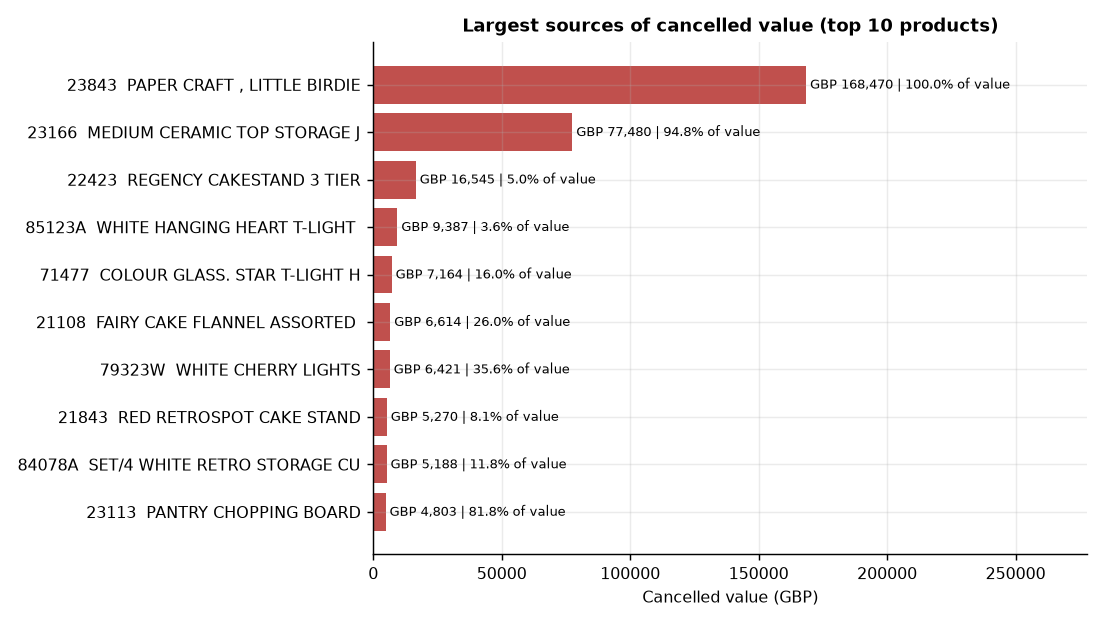

In [3]:
returns = analysis["returns"]
overview = pd.DataFrame(
    [
        (
            "Unit return rate",
            f"{returns['unit_rate']:.2%}",
            f"{returns['cancelled_units']:,.0f} of {returns['purchased_units']:,.0f} units",
        ),
        (
            "Value return rate",
            f"{returns['value_rate']:.2%}",
            f"{gbp(returns['cancelled_value'])} of {gbp(returns['gross_value'])}",
        ),
        (
            "Line return rate",
            f"{returns['line_rate']:.2%}",
            f"{returns['cancelled_lines']:,} of {returns['ordinary_lines']:,} lines",
        ),
    ],
    columns=["metric", "value", "basis"],
)
display(overview.set_index("metric"))

product_returns = pd.read_csv(TABLES / "product_return_rates.csv")
cancelled_value = product_returns["cancelled_value"]
top2_share = cancelled_value.nlargest(2).sum() / cancelled_value.sum()
print(f"Two products account for {top2_share:.1%} of all cancelled value")
return_columns = [
    "description",
    "gross_value",
    "cancelled_value",
    "ordinary_lines",
    "value_return_rate",
    "line_return_rate",
]
display(product_returns.head(6).set_index("stock_code")[return_columns].round(3))
display(Image(filename=str(FIGURES / "product_returns.png")))

Value and line rates are not interchangeable. Two products account for 34.3% of all
cancelled value, but both are **bulk-order artefacts**, not quality problems:

- `23843 PAPER CRAFT, LITTLE BIRDIE` sold 80,995 units on **one line** and had all
  80,995 cancelled — 100% value return, but 1 of 1 line.
- `23166 MEDIUM CERAMIC TOP STORAGE JAR` sold 78,033 units over 250 lines and had
  74,494 cancelled on 10 lines — 94.8% of value but a 4.0% line rate.

`23113 PANTRY CHOPPING BOARD` is the opposite: 81.8% of value returned on an 11.8%
line rate, i.e. fewer, larger cancellations. The line rate is the right quality signal;
the value rate is the right cash-exposure signal. Neither alone justifies delisting a
product.


## Market-basket association rules

Baskets (ordinary invoices): 44,749
Distinct items: 5,273 | eligible after 0.1% item support: 3,123
Items per basket — mean 22.3, median 13, max 1,108
Directed rules emitted: 67,317
Thresholds: item support ≥ 0.1%, pair support ≥ 0.2%, confidence ≥ 5%


Rules at ≥ 0.5% pair support: 5,844 | strongest pair support overall: 3.19%


,antecedent_description,consequent_description,pair_baskets,support_pair,confidence,lift
0,HERB MARKER THYME,HERB MARKER ROSEMARY,232,0.0052,0.9317,165.4518
1,HERB MARKER ROSEMARY,HERB MARKER THYME,232,0.0052,0.9206,165.4518
2,HERB MARKER THYME,HERB MARKER PARSLEY,224,0.0050,0.8996,161.6712
3,HERB MARKER PARSLEY,HERB MARKER THYME,224,0.0050,0.8996,161.6712
4,HERB MARKER PARSLEY,HERB MARKER ROSEMARY,225,0.0050,0.9036,160.4597
5,HERB MARKER ROSEMARY,HERB MARKER PARSLEY,225,0.0050,0.8929,160.4597
6,REGENCY TEA PLATE PINK,REGENCY TEA PLATE GREEN,278,0.0062,0.9115,107.0541
7,REGENCY TEA PLATE GREEN,REGENCY TEA PLATE PINK,278,0.0062,0.7297,107.0541
8,CHRISTMAS TREE HEART DECORATION,CHRISTMAS TREE STAR DECORATION,240,0.0054,0.7430,102.6236
9,CHRISTMAS TREE STAR DECORATION,CHRISTMAS TREE HEART DECORATION,240,0.0054,0.7407,102.6236


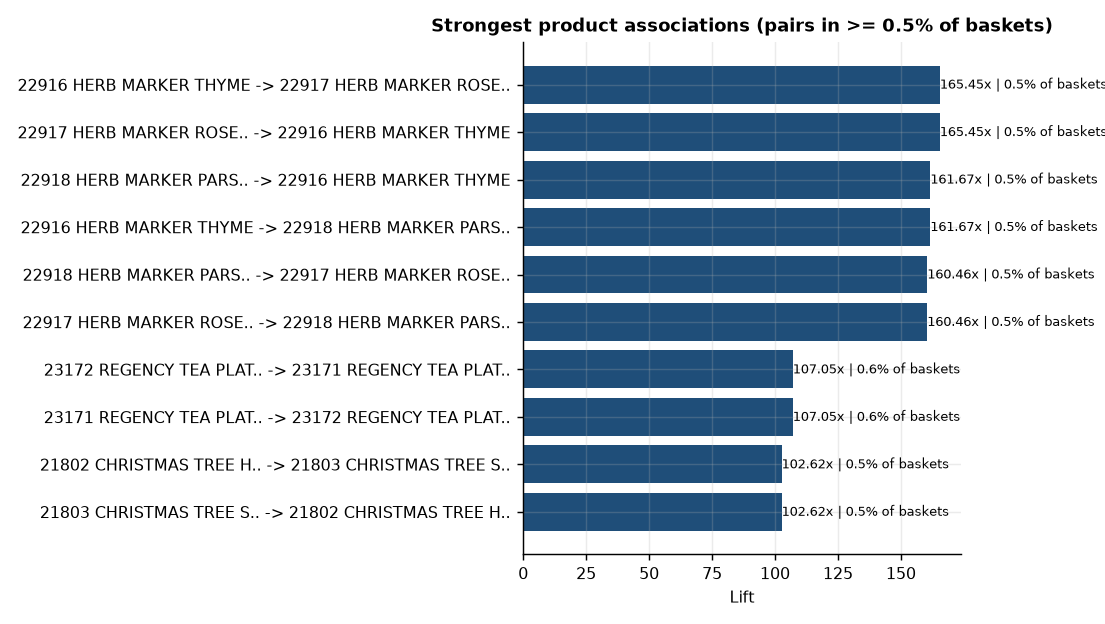

In [4]:
baskets = analysis["baskets"]
print(f"Baskets (ordinary invoices): {baskets['baskets']:,}")
print(
    f"Distinct items: {baskets['items']:,} | "
    f"eligible after 0.1% item support: {baskets['eligible_items']:,}"
)
print(
    f"Items per basket — mean {baskets['avg_items']:.1f}, "
    f"median {baskets['median_items']:.0f}, max {baskets['max_items']:,}"
)
print(f"Directed rules emitted: {baskets['rules']:,}")
print(
    f"Thresholds: item support ≥ {baskets['min_item_support']:.1%}, "
    f"pair support ≥ {baskets['min_pair_support']:.1%}, "
    f"confidence ≥ {baskets['min_confidence']:.0%}"
)

rules = pd.read_csv(TABLES / "association_rules.csv")
material = rules.loc[rules["support_pair"] >= 0.005].sort_values("lift", ascending=False)
print(
    f"Rules at ≥ 0.5% pair support: {len(material):,} | "
    f"strongest pair support overall: {rules['support_pair'].max():.2%}"
)
rule_columns = [
    "antecedent_description",
    "consequent_description",
    "pair_baskets",
    "support_pair",
    "confidence",
    "lift",
]
display(material.head(10)[rule_columns].reset_index(drop=True).round(4))
display(Image(filename=str(FIGURES / "basket_rules.png")))

Baskets are large on average (22.3 items) but the median is 13 and the maximum is
1,108 — the mean is pulled by wholesale pallets, so use the median when describing a
typical basket.

Two structural patterns stand out. **Matching sets** dominate the strongest rules:
herb markers (thyme → rosemary at 93.2% confidence, 165× lift) and Regency tea plates
(pink → green at 91.1%). **Direction matters**: herb marker rosemary → thyme is 92.1%,
while tea-plate green → pink is only 73.0%, so the pink plate is the better anchor for
a bundle even though the pair is symmetric in support.

The lift values are huge because the consequent is rare, not because the pair is
common: the strongest material rule appears in only 0.52% of baskets. Lift ranks
affinity; support ranks reach. A bundle decision needs both.


## So what?

1. **Concentrate merchandising on the top 20%.** 1,048 products (19.9% of the range)
   generate 80.0% of revenue (Gini 0.770). Range reviews, stock depth and photography
   budgets should be prioritised by cumulative revenue share, not by SKU count.
2. **Do not delist on value-return rate alone.** 34.3% of cancelled value sits in two
   bulk-cancelled products with 100% and 94.8% value return but 1-of-1 and 10-of-250
   cancelled lines. Use line return rate for quality, value return rate for cash risk.
3. **Bundle the matching sets; they are near-deterministic.** Herb markers and Regency
   tea plates co-occur at 89–93% confidence with ~160× lift. Even a modest attach rate
   gain compounds across every basket containing the anchor item.
4. **Respect the reach ceiling.** No pair appears in more than 3.19% of baskets, and
   the strongest material rule reaches 0.52%. Bundles built on these rules will deepen
   existing baskets, not create a mass-market promotion.
5. **Median basket is 13 items, not 22.** The mean is inflated by wholesale orders up
   to 1,108 items; merchandising targets and free-shipping thresholds should be set on
   the median or p75, not the mean.


## Limitations

- Basket rules are co-occurrence, not causation: a matching-set pair is bought
  together because it is a set, not because one item causes the other. Test bundles
  before claiming incremental revenue.
- Cancellation and adjustment lines are excluded from baskets, so a basket is an
  ordinary purchase only.
- Products with item support below 0.1% are excluded from rule generation, so the
  longest-tail SKUs cannot appear in any rule.
- The product return table uses signed cancellation sums (one manual `M` line is a
  positive reversal), so refunded value is not overstated.
